<a href="https://colab.research.google.com/github/dhatrisrivadupu/ML-projects/blob/main/week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#import libraries
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#Load MNIST Dataset
mnist = fetch_openml('mnist_784')
x = mnist.data
y = mnist.target.astype(int)

In [ ]:
print("dataset shape: ", x.shape)

dataset shape:  (70000, 784)


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [ ]:
#standard Scaler
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [ ]:
#model- Simple perceptron
perceptron = Perceptron()
perceptron.fit(x_train_scaled, y_train)
y_pred = perceptron.predict(x_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy: ", accuracy)

Accuracy:  0.8759285714285714


In [ ]:
#MULTILAYER PERCEPTRON
mlp = MLPClassifier(hidden_layer_sizes=(100,), max_iter=20, random_state=42)
mlp.fit(x_train_scaled, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier(max_iter=20, random_state=42)

In [ ]:
#prediction accuracy
y_pred = mlp.predict(x_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy: ", accuracy)


Accuracy:  0.9729285714285715


In [ ]:
# Comparison
print("\nPerformance Comparison")
perceptron_accuracy = 0.8759285714285714
mlp_accuracy = accuracy
print("Perceptron Accuracy : {:.2f}%".format(perceptron_accuracy * 100))
print("MLP Accuracy : {:.2f}%".format(mlp_accuracy * 100))


Performance Comparison
Perceptron Accuracy : 87.59%
MLP Accuracy : 97.29%


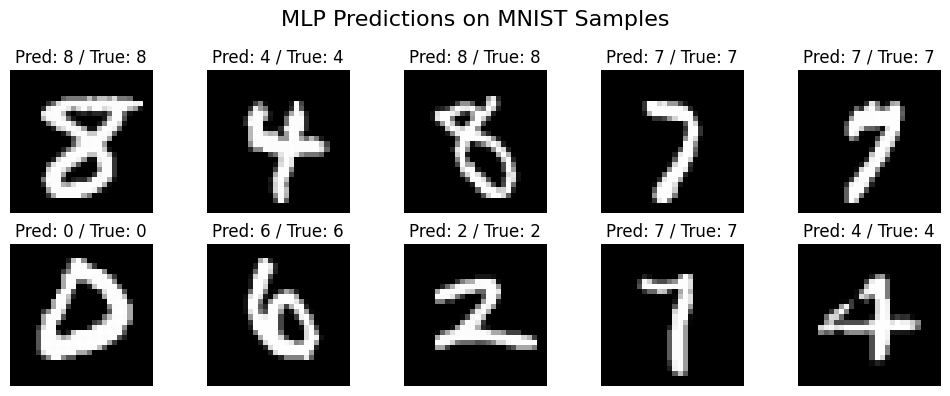

In [ ]:
#Visualization
plt.figure(figsize=(10, 4))
plt.suptitle("MLP Predictions on MNIST Samples", fontsize=16)
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test.iloc[i].values.reshape(28, 28), cmap='gray')
    plt.title(f"Pred: {y_pred[i]} / True: {y_test.iloc[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()